# 🧊 PyVista入門（実データ編）：公開ECoGデータでCTと電極を描く

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Murakami-Shoya/study-notebooks/blob/main/notebooks/2026-10-20_pyvista-real-data.ipynb)

**解説ページ**: [Notion教材ページ](https://app.notion.com/p/3ff3834a206d811d970ce1a88219e2e0)（「実データで描く」の節）／合成データ編：[2026-10-20_pyvista-basics.ipynb](2026-10-20_pyvista-basics.ipynb)

**データ**: [MNE-Python misc data](https://github.com/mne-tools/mne-misc-data)（タグ 0.27、BSD-3-Clause）の `ecog/`。実行時に約53 MBをダウンロードする（リポジトリには含めない）

## 何を確かめるか

1. CTのボクセル番号は、4×4行列の連鎖（ボクセル → CTスキャナRAS → T1スキャナRAS → FreeSurfer表面RAS）で脳表と同じ座標に移せる。移したCTの金属は電極座標と2 mm以内で重なる
2. 電極座標（head座標、m）は head→MRI の変換で右半球の脳表（pial）に載り、MNI座標でも右半球（x > 0）になる
3. 実CTでも、CT-Boneの伝達関数＋`shade=True` で3D Slicerに近い見た目になり、+200 HU ずらすと骨と金属だけが残る
4. ボリュームに切断面（clipping plane）を入れると、頭蓋の下の脳表と電極（色＝電極ごとのβ帯域パワー）を同じ図に描ける

## どんなデータを用意するか

てんかん患者の術後CT・T1 MRI・FreeSurferの脳表・ECoG記録（右半球に硬膜下グリッドとストリップ）。正解の目安は「電極座標とCTの金属が重なること」。

| 変数 | 形（shape） | 中身 |
|---|---|---|
| `ct_vol` | `(256, 256, 137)` | 術後CT [HU]。元は `(512, 512, 137)`・0.49×0.49×1.25 mm を面内で2つおきに間引く |
| `ct.affine` | `(4, 4)` | CTボクセル → CTスキャナRAS [mm] |
| `REG` | `(4, 4)` | T1スキャナRAS → CTスキャナRAS（MNEのチュートリアルにある位置合わせ結果） |
| `t1` | `(256, 256, 256)` | T1 MRI。座標の変換行列（ヘッダ）だけ使う |
| `lh_v`, `rh_v` | `(112997, 3)`, `(109380, 3)` | 左右の脳表（pial）の頂点 [mm、表面RAS]。面は `(n_faces, 3)` |
| `ecog` | `(n_electrodes, n_times)` = `(320, 113)` | ECoG信号 [V]、160 Hz・0.7秒 |
| `elec_head` → `elec_surf`, `elec_mni` | `(320, 3)` | 電極座標：head座標 [m] → 表面RAS [mm]、MNI [mm] |
| `beta_pow` | `(320,)` | 電極ごとのβ帯域（20〜30 Hz）パワーの log10 |

## シナリオ一覧

| # | 使うデータ | 何を動かすか | 確かめること | 期待する結果 | 解説の節 |
|---|---|---|---|---|---|
| R1 | 全ファイル | ダウンロードと読み込み | 形と大きさ | 表の形どおり、合計約53 MB | 10. 実データで描く |
| R2 | `ct_vol`, `elec_head`, `rh_v` | 4×4行列の連鎖、head→MRI、MNI | 座標が合うか | 金属との距離の中央値 < 2 mm、脳表との距離 < 3 mm、MNIのx > 0 | 10 |
| R3 | `ct_vol`, `M` | CT-Bone、shift 0／+200 HU | 実CTの見た目 | 頭蓋・開頭部・電極の配線が陰影付きで見える | 5・7 |
| R4 | `rh_v`, `elec_surf`, `ecog` | β帯域パワー、凸包への射影 | 脳表＋電極の色 | グリッドが脳表の上に並び、色が電極ごとに違う | 6 |
| R5 | すべて | 切断面＋脳表＋電極 | 重ね描きの図 | 頭蓋の切り口の中に脳表と電極が見える図をpngで保存 | 6・10 |

## 準備：環境・ダウンロード・補助関数

In [1]:
# 環境の準備：足りないパッケージを入れ、画面のないLinux（Colabなど）では仮想ディスプレイXvfbを起動する
import os, sys, time, shutil, subprocess, importlib.util
IN_COLAB = 'google.colab' in sys.modules
missing = [p for p in ['pyvista', 'mne', 'pooch', 'nibabel'] if importlib.util.find_spec(p) is None]
if missing:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *missing], check=True)
if IN_COLAB and shutil.which('Xvfb') is None:
    subprocess.run('apt-get -qq update && apt-get -qq install -y xvfb', shell=True, check=True)
if sys.platform.startswith('linux') and not os.environ.get('DISPLAY') and shutil.which('Xvfb'):
    subprocess.Popen(['Xvfb', ':99', '-screen', '0', '1280x1024x24'],
                     stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    os.environ['DISPLAY'] = ':99'
    time.sleep(2)  # Xvfbの起動待ち
print('Colab:', IN_COLAB, '| missing installed:', missing, '| DISPLAY:', os.environ.get('DISPLAY'))

Colab: False | missing installed: [] | DISPLAY: :99


In [2]:
# ライブラリと定数（URL・ハッシュ・位置合わせ行列）
import numpy as np, pyvista as pv, nibabel as nib, mne, pooch, matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.colors import ListedColormap
from scipy.spatial import cKDTree, ConvexHull
from vtkmodules.vtkCommonDataModel import vtkPlane
pv.OFF_SCREEN = True;  mne.set_log_level('WARNING')
BASE, DATA = 'https://raw.githubusercontent.com/mne-tools/mne-misc-data/0.27/ecog/', Path('mne_misc_ecog')
REG = np.array([[0.99982382, -0.00414586, -0.01830679, 0.15413965], [0.00549597, 0.99721885, 0.07432601, -1.54316131],
                [0.01794773, -0.07441352, 0.99706595, -1.84162514], [0, 0, 0, 1]])   # MNE ieeg_localize チュートリアルの値
WIN, CLIM, BETA = (700, 600), (-1000, 3071), (20, 30)   # 画像 [px]、HUの範囲、β帯域 [Hz]
def snap(p, azimuth=0):                                             # Plotterを右から撮って (H, W, 3) を返す
    p.view_yz(); p.camera.azimuth, p.camera.elevation = azimuth, 10; p.camera.zoom(1.4)
    img = p.screenshot(return_img=True); p.close(); return img
print('pyvista', pv.__version__, '| mne', mne.__version__)

/workspace/pvenv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


pyvista 0.49.1 | mne 1.13.2


In [3]:
# 6ファイルをハッシュ確認つきでダウンロード（2回目以降はキャッシュを使う）
FILES = {  # 相対パス: sha256
    'sample_ecog_CT.mgz': '3203c874e8b57eb2da66a7f949d2c4b1ef48813f6699b7a14bf04af63cadf528',
    'sample_ecog_ieeg.fif': '81a917ded01065e39cae74476edffdf9b0a73213da9487800aeaaa38d0fc5f36',
    'sample_ecog/mri/T1.mgz': '3feb26485214f2de66247d9817252eaece1b2cb4ba563ebf120b39e5ed787451',
    'sample_ecog/mri/transforms/talairach.xfm': '152226fcfd60a41f1676c548f1ae86ec3dcbbc38c39458246781e4f36ccf285b',
    'sample_ecog/surf/lh.pial': 'fb81c971c76d1a95379b14a3f0f3574e008d25c70374275f4311ad8f414bddce',
    'sample_ecog/surf/rh.pial': '56cea047fc60b5e42480b9439ea63091b45e2ee04b3a28f04a975f362ecf8790',
}
t0 = time.time()
for rel, sha in FILES.items():
    pooch.retrieve(BASE + rel, known_hash=f'sha256:{sha}', fname=Path(rel).name,
                   path=DATA / Path(rel).parent, progressbar=False)
size_mb = sum((DATA / rel).stat().st_size for rel in FILES) / 1e6
print(f'downloaded: {size_mb:.1f} MB in {time.time() - t0:.1f} s')

downloaded: 53.3 MB in 1.2 s


In [4]:
# CT-Boneの伝達関数（3D Slicer presets.xml）→ 不透明度 (n,) と色マップ。n≠256（0.49.1の不具合回避）
HU_PTS, OPA_PTS = np.array([-3024, -16.4458, 641.385, 3071]), np.array([0, 0, 0.715686, 0.705882])
RGB_PTS = np.array([[0, 0, 0], [0.729, 0.255, 0.302], [0.906, 0.816, 0.553], [1, 1, 1]])
def ct_bone_tf(shift=0.0, n=128):
    hu = np.linspace(*CLIM, n)
    rgb = np.stack([np.interp(hu, HU_PTS + shift, RGB_PTS[:, k]) for k in range(3)], 1)
    return np.interp(hu, HU_PTS + shift, OPA_PTS), ListedColormap(rgb)
# FreeSurferの頂点 (n_v, 3) と面 (n_f, 3) → PolyData
def fs_mesh(v, f):
    return pv.PolyData(v, np.hstack([np.full((len(f), 1), 3), f]).ravel())
# 画像を並べて表示（図の文字は英語）: list of (H, W, 3)
def show(images, titles):
    fig, axs = plt.subplots(1, len(images), figsize=(5.5 * len(images), 4.8), squeeze=False)
    for ax, img, t in zip(axs[0], images, titles): ax.imshow(img); ax.set_title(t); ax.axis('off')
    plt.tight_layout(); plt.show()

## R1. ダウンロードしたファイルを読み込む
CT・T1・脳表・ECoGを読み、形を表と照らす。CTは面内を2つおきに間引いて軽くする。

In [5]:
# CT・T1・脳表・ECoGを読み込み、形を確かめる
ct, t1 = nib.load(DATA / 'sample_ecog_CT.mgz'), nib.load(DATA / 'sample_ecog/mri/T1.mgz')
ct_vol = np.asarray(ct.dataobj, dtype=np.float32)[::2, ::2, :]      # (512,512,137) → (256,256,137)
print('CT:', tuple(map(int, ct.shape)), '->', ct_vol.shape, '| voxel [mm]:', np.round(ct.header.get_zooms(), 2), '| T1:', tuple(map(int, t1.shape)))
(lh_v, lh_f), (rh_v, rh_f) = [nib.freesurfer.read_geometry(DATA / f'sample_ecog/surf/{h}.pial') for h in ('lh', 'rh')]
print('lh_v:', lh_v.shape, '| rh_v:', rh_v.shape, '| rh_f:', rh_f.shape)
raw = mne.io.read_raw_fif(DATA / 'sample_ecog_ieeg.fif').pick('ecog').load_data()
ecog = raw.get_data()                                               # (n_electrodes, n_times)
pos = raw.get_montage().get_positions()
elec_head = np.array([pos['ch_pos'][ch] for ch in raw.ch_names])    # (320, 3) [m]
print('ecog:', ecog.shape, '| sfreq:', raw.info['sfreq'], '| elec_head:', elec_head.shape, pos['coord_frame'])
assert ct_vol.shape == (256, 256, 137) and ecog.shape[0] == elec_head.shape[0] == 320

CT: (512, 512, 137) -> (256, 256, 137) | voxel [mm]: [0.49 0.49 1.25] | T1: (256, 256, 256)
lh_v: (112997, 3) | rh_v: (109380, 3) | rh_f: (218756, 3)
ecog: (320, 113) | sfreq: 160.0 | elec_head: (320, 3) head


**観察**：形は表どおり。電極座標は `head` 座標（m）で入っているので、そのままではCT・脳表（mm、表面RAS）と重ならない。

## R2. 座標をそろえる：ボクセル → スキャナRAS → 表面RAS、head → MRI、MNI
CTは4×4行列の積 `M` で、電極は head→MRI の変換で、どちらもFreeSurferの表面RAS [mm] に移す。CTの金属（> 2500 HU）と電極の距離、脳表と電極の距離、MNIのxを見る。

In [6]:
# CTボクセル → 表面RAS の4×4行列を組み、電極も表面RASとMNIへ移す
vox2ct = ct.affine @ np.diag([2, 2, 1, 1])                          # 間引き後のボクセル → CTスキャナRAS
flip = np.eye(4);  flip[0, 0], flip[0, 3] = -1, ct_vol.shape[0] - 1   # i軸を反転して行列式を正に
ct_vol, vox2ct = ct_vol[::-1].copy(), vox2ct @ flip
ras2surf = t1.header.get_vox2ras_tkr() @ np.linalg.inv(t1.affine)   # T1スキャナRAS → 表面RAS
M = ras2surf @ np.linalg.inv(REG) @ vox2ct                          # (4,4) @ (4,4) @ (4,4) -> (4,4)
print('M:', M.shape, '| det:', np.linalg.det(M[:3, :3]).round(3))
trans = mne.coreg.estimate_head_mri_t('sample_ecog', DATA)          # head → MRI（表面RAS）[m]
elec_surf = mne.transforms.apply_trans(trans, elec_head) * 1000      # (320, 3) [mm]
elec_mni = mne.head_to_mni(elec_head, 'sample_ecog', trans, subjects_dir=DATA)   # (320, 3) [mm]
metal = nib.affines.apply_affine(M, np.argwhere(ct_vol > 2500))     # (n_metal, 3) [mm]
d_metal, d_pial = cKDTree(metal).query(elec_surf)[0], cKDTree(rh_v).query(elec_surf)[0]
print('elec_surf:', elec_surf.shape, '| metal:', metal.shape, '| median dist metal / pial [mm]:', np.median(d_metal).round(2), np.median(d_pial).round(2))
assert np.linalg.det(M[:3, :3]) > 0 and np.median(d_metal) < 2 and np.median(d_pial) < 3 and (elec_mni[:, 0] > 0).all()

M: (4, 4) | det: 1.192


elec_surf: (320, 3) | metal: (8726, 3) | median dist metal / pial [mm]: 0.53 1.55


**観察**：CTの金属と電極は中央値で約0.5 mm、脳表とは約1.6 mmで重なり、MNIでも全電極が右半球（x > 0）だった。行列式が負（鏡映を含む）の `user_matrix` をボリュームに渡すと左右が反転して描かれたため（PyVista 0.49.1・VTK 9.7.1で確認）、i軸を反転して正にした。

## R3. 実CTのボリュームレンダリング（CT-Bone、陰影あり）
`ImageData` をボクセル番号のまま作り、`user_matrix=M` で表面RASに置く。CT-Boneの伝達関数を shift 0 と +200 HU で描き比べる。

grid.n_points: 8978432 | HU range: -3024.0 3071.0


image: (600, 700, 3)


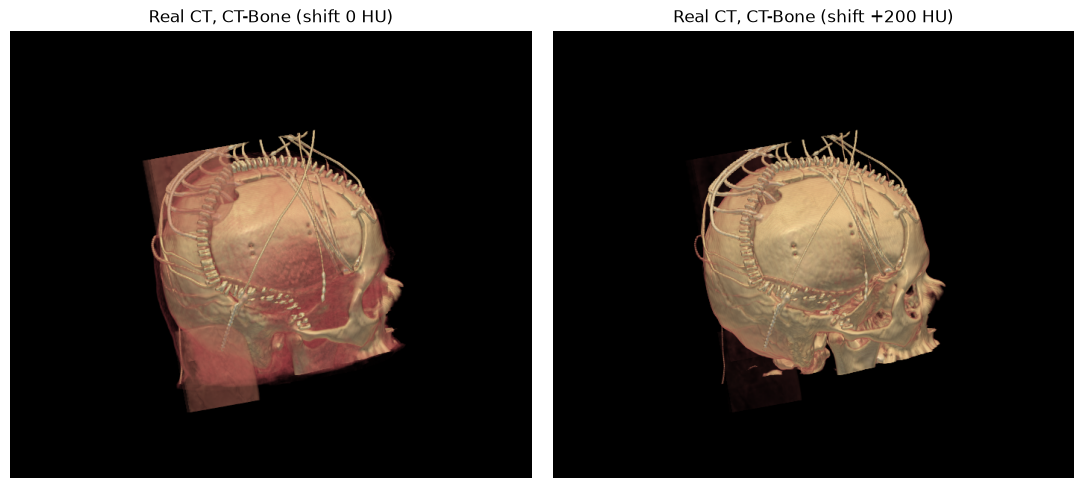

In [7]:
# 実CTをCT-Boneで描く（shiftで伝達関数をずらし、clipで切断面を入れられる）
grid = pv.ImageData(dimensions=ct_vol.shape);  grid['HU'] = ct_vol.ravel(order='F')   # (n_voxels,)
print('grid.n_points:', grid.n_points, '| HU range:', grid['HU'].min(), grid['HU'].max())
def add_ct(shift=0.0, clip_x=None):                                 # → CTを載せたPlotter
    p = pv.Plotter(window_size=WIN); p.set_background('black'); opa, cmap = ct_bone_tf(shift)
    act = p.add_volume(grid, scalars='HU', clim=CLIM, opacity=opa, cmap=cmap, shade=True, user_matrix=M,
                       opacity_unit_distance=1.0, show_scalar_bar=False)
    act.prop.interpolation_type, act.prop.ambient, act.prop.diffuse, act.prop.specular = 'linear', 0.1, 0.9, 0.2
    if clip_x is not None:                                          # x > clip_x の側を切り落とす
        plane = vtkPlane(); plane.SetOrigin(clip_x, 0, 0); plane.SetNormal(-1, 0, 0); act.mapper.AddClippingPlane(plane)
    return p
imgs = [snap(add_ct(shift)) for shift in (0, 200)]                  # 2枚 × (H, W, 3)
print('image:', imgs[0].shape);  show(imgs, ['Real CT, CT-Bone (shift 0 HU)', 'Real CT, CT-Bone (shift +200 HU)'])

**観察**：shift 0 では皮膚と頭を支える台が赤く薄く写り、+200 HU では頭蓋・開頭部の縁・電極の配線だけが陰影付きで残った。電極そのものは頭蓋の下にあるので見えない。

## R4. 脳表＋電極（色＝β帯域パワー）
電極ごとに20〜30 HzのパワーをFFTで求めて log10 を取る。電極は脳溝に沈んで見えにくいので、表示用に右半球の凸包（全体を包む凸な面）へ射影する。

beta_pow: (320,) | elec_disp: (320, 3) | move median/max [mm]: 8.6 14.3


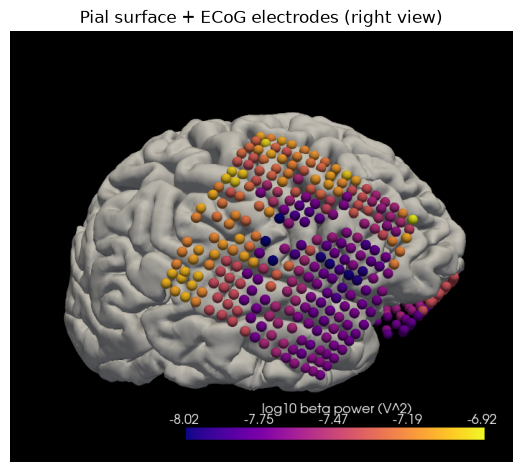

In [8]:
# β帯域パワーを求め、凸包に射影した電極を脳表に重ねる
freqs = np.fft.rfftfreq(ecog.shape[1], 1 / raw.info['sfreq'])           # (57,)
spec = np.abs(np.fft.rfft(ecog - ecog.mean(1, keepdims=True), axis=1)) ** 2   # (320, 57)
beta_pow = np.log10(spec[:, (freqs >= BETA[0]) & (freqs <= BETA[1])].mean(1))   # (320,)
hull = fs_mesh(rh_v, ConvexHull(rh_v).simplices).clean()             # 右半球の凸包
elec_disp = hull.find_closest_cell(elec_surf, return_closest_point=True)[1]   # (320, 3)
move = np.linalg.norm(elec_disp - elec_surf, axis=1)
print('beta_pow:', beta_pow.shape, '| elec_disp:', elec_disp.shape, '| move median/max [mm]:', np.median(move).round(1), move.max().round(1))
balls = pv.PolyData(elec_disp);  balls['beta_pow'] = beta_pow
balls = balls.glyph(geom=pv.Sphere(radius=1.8), scale=False, orient=False)
brain = fs_mesh(lh_v, lh_f).merge(fs_mesh(rh_v, rh_f))
bar = {'title': 'log10 beta power (V^2)', 'color': 'white'}
p = pv.Plotter(window_size=WIN); p.set_background('black'); p.add_mesh(brain, color='lightgray', smooth_shading=True)
p.add_mesh(balls, scalars='beta_pow', cmap='plasma', smooth_shading=True, scalar_bar_args=bar)
img_r4 = snap(p);  show([img_r4], ['Pial surface + ECoG electrodes (right view)'])

**観察**：グリッドとストリップが脳表の上に並び、色は電極ごとに違った。凸包への射影で電極は中央値で数mm動くので、図は表示用。解析には `elec_surf` をそのまま使う。

## R5. CT（切断面つき）＋脳表＋電極を重ねる
CTを x > 30 mm の側で切り落とし（Slicerで関心領域を切り抜くのと同じ）、R4の脳表と電極を重ねてpngで保存する。

img_r5: (600, 700, 3) | saved: True


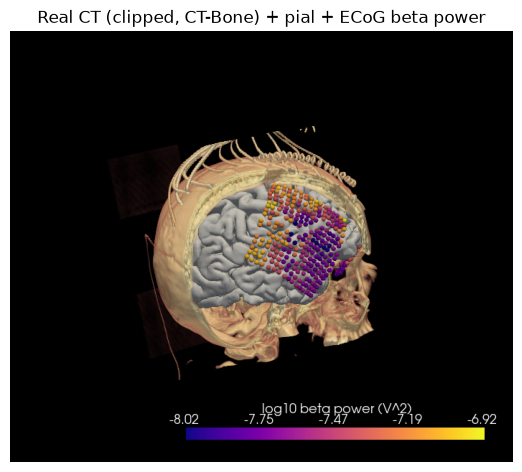

In [9]:
# 切断面つきのCT・脳表・電極を1枚に重ねて保存する
p = add_ct(shift=200, clip_x=30)
p.add_mesh(brain, color='lightgray', smooth_shading=True)
p.add_mesh(balls, scalars='beta_pow', cmap='plasma', smooth_shading=True, scalar_bar_args=bar)
img_r5 = snap(p, azimuth=-20);  plt.imsave('pyvista_real_ct_pial_ecog.png', img_r5)
print('img_r5:', img_r5.shape, '| saved:', os.path.exists('pyvista_real_ct_pial_ecog.png'))
assert img_r5.shape == (WIN[1], WIN[0], 3)
show([img_r5], ['Real CT (clipped, CT-Bone) + pial + ECoG beta power'])

**観察**：頭蓋の切り口の内側に脳表と電極が見え、開頭部の縁や配線の位置と電極グリッドの位置が合っていた。

## まとめ
- 実データでは座標の連鎖（ボクセル → スキャナRAS → 表面RAS、head → MRI）を4×4行列で明示し、金属・脳表との距離で検算する。
- 描画は合成データ編と同じ（CT-Bone＋`shade`、`glyph`）。加えて `user_matrix` の行列式を正にし、切断面で頭蓋の下を見せる。